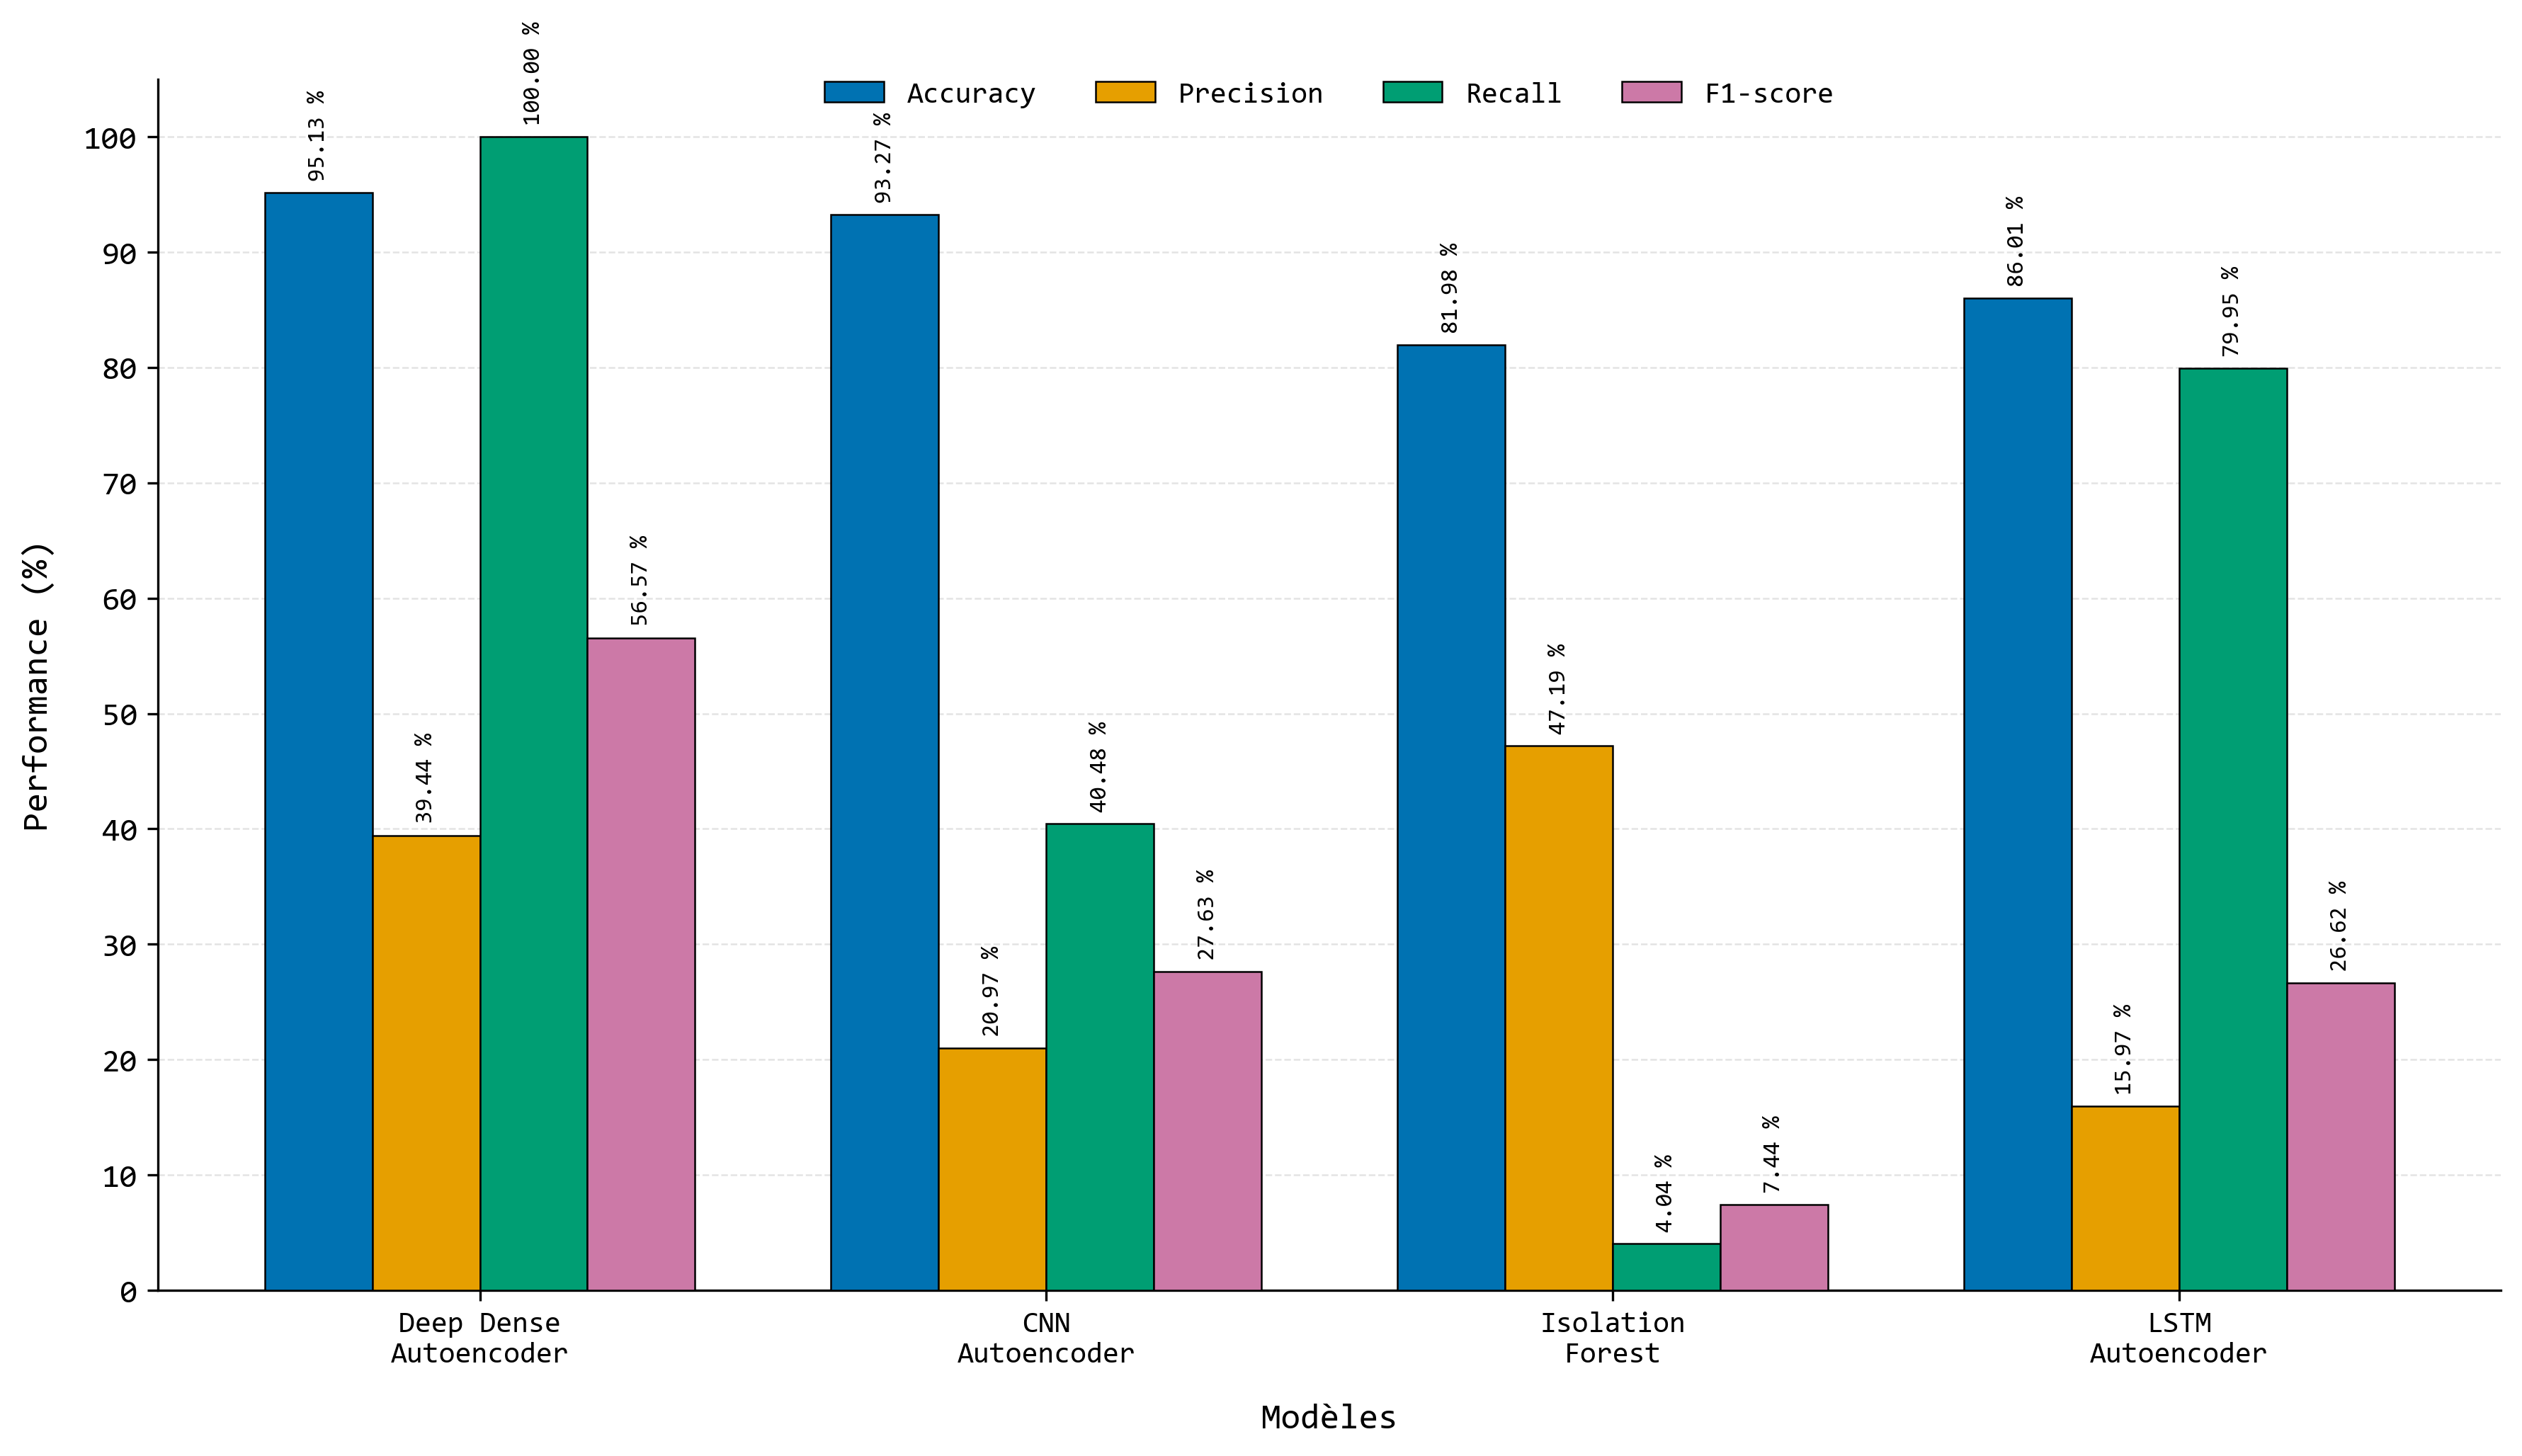

In [2]:
# ============================================================
# Comparaison des performances des quatre modèles
# Accuracy - Precision - Recall - F1-score
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Configuration graphique générale
# ============================================================

# Police demandée pour l'ensemble de la figure
plt.rcParams["font.family"] = "Consolas"

# Taille générale des textes
plt.rcParams["font.size"] = 11

# Qualité d'affichage dans le notebook
plt.rcParams["figure.dpi"] = 120


# ============================================================
# Résultats expérimentaux réels
# ============================================================
#
# Valeurs extraites des résultats obtenus expérimentalement
# avec les quatre modèles.
#
# Toutes les valeurs sont exprimées en pourcentage.
# ============================================================

results = {

    "Deep Dense\nAutoencoder": {
        "Accuracy": 95.13,
        "Precision": 39.44,
        "Recall": 100.00,
        "F1-score": 56.57
    },

    "CNN\nAutoencoder": {
        "Accuracy": 93.27,
        "Precision": 20.97,
        "Recall": 40.48,
        "F1-score": 27.63
    },

    "Isolation\nForest": {
        "Accuracy": 81.98,
        "Precision": 47.19,
        "Recall": 4.04,
        "F1-score": 7.44
    },

    "LSTM\nAutoencoder": {
        "Accuracy": 86.01,
        "Precision": 15.97,
        "Recall": 79.95,
        "F1-score": 26.62
    }
}


# ============================================================
# Vérification des données
# ============================================================

missing_values = []

for model, metrics in results.items():

    for metric, value in metrics.items():

        if value is None:

            missing_values.append(
                f"{model.replace(chr(10), ' ')} - {metric}"
            )


if missing_values:

    print("=" * 65)
    print("VALEURS EXPÉRIMENTALES MANQUANTES")
    print("=" * 65)

    for item in missing_values:
        print(f" - {item}")

    raise ValueError(
        "\nComplétez les valeurs None dans la section "
        "'Résultats expérimentaux' avant de générer la figure."
    )


# ============================================================
# Préparation des données
# ============================================================

models = list(
    results.keys()
)

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]


# Conversion des résultats en matrice NumPy
values = np.array(

    [
        [
            results[model][metric]
            for metric in metrics
        ]

        for model in models
    ],

    dtype=float
)


# ============================================================
# Vérification de l'intervalle des valeurs
# ============================================================

if np.any(values < 0) or np.any(values > 100):

    raise ValueError(
        "Toutes les métriques doivent être comprises "
        "entre 0 et 100 %."
    )


# ============================================================
# Paramètres du diagramme
# ============================================================

x = np.arange(
    len(models)
)

bar_width = 0.19


# Palette sobre adaptée aux publications scientifiques
colors = [
    "#0072B2",   # bleu
    "#E69F00",   # orange
    "#009E73",   # vert
    "#CC79A7"    # violet
]


# ============================================================
# Création de la figure
# ============================================================

fig, ax = plt.subplots(

    figsize=(
        12,
        7
    ),

    dpi=300
)


# ============================================================
# Création des barres groupées
# ============================================================

bars_collection = []


for i, metric in enumerate(metrics):

    offset = (
        i - (len(metrics) - 1) / 2
    ) * bar_width

    bars = ax.bar(

        x + offset,

        values[:, i],

        width=bar_width,

        label=metric,

        color=colors[i],

        edgecolor="black",

        linewidth=0.6,

        zorder=3
    )

    bars_collection.append(
        bars
    )


# ============================================================
# Affichage des valeurs au-dessus des barres
# ============================================================

for bars in bars_collection:

    for bar in bars:

        height = bar.get_height()

        ax.annotate(

            f"{height:.2f} %",

            xy=(
                bar.get_x()
                +
                bar.get_width() / 2,

                height
            ),

            xytext=(
                0,
                4
            ),

            textcoords="offset points",

            ha="center",

            va="bottom",

            fontsize=8,

            fontfamily="Consolas",

            rotation=90
        )


# ============================================================
# Configuration des axes
# ============================================================

ax.set_xlabel(

    "Modèles",

    fontsize=12,

    fontfamily="Consolas",

    labelpad=12
)


ax.set_ylabel(

    "Performance (%)",

    fontsize=12,

    fontfamily="Consolas",

    labelpad=10
)


# Axe X
ax.set_xticks(
    x
)

ax.set_xticklabels(

    models,

    fontsize=10,

    fontfamily="Consolas"
)


# Axe Y
ax.set_ylim(
    0,
    105
)

ax.set_yticks(
    np.arange(
        0,
        101,
        10
    )
)


# ============================================================
# Configuration de la grille
# ============================================================

ax.grid(

    axis="y",

    linestyle="--",

    linewidth=0.6,

    alpha=0.35,

    zorder=0
)


# Suppression des bordures inutiles
ax.spines["top"].set_visible(
    False
)

ax.spines["right"].set_visible(
    False
)


# ============================================================
# Légende
# ============================================================

legend = ax.legend(

    loc="upper center",

    bbox_to_anchor=(
        0.5,
        1.02
    ),

    ncol=4,

    frameon=False,

    fontsize=10
)


# Application explicite de Consolas à la légende
for text in legend.get_texts():

    text.set_fontfamily(
        "Consolas"
    )


# ============================================================
# Application de Consolas aux graduations
# ============================================================

for label in ax.get_xticklabels():

    label.set_fontfamily(
        "Consolas"
    )


for label in ax.get_yticklabels():

    label.set_fontfamily(
        "Consolas"
    )


# ============================================================
# Optimisation de la mise en page
# ============================================================

plt.tight_layout()


# ============================================================
# Sauvegarde PDF vectorielle
# ============================================================

plt.savefig(

    "comparaison_metriques_modeles.pdf",

    format="pdf",

    bbox_inches="tight"
)


# ============================================================
# Sauvegarde PNG haute résolution
# ============================================================

plt.savefig(

    "comparaison_metriques_modeles.png",

    format="png",

    dpi=300,

    bbox_inches="tight"
)


# ============================================================
# Affichage dans le notebook
# ============================================================

plt.show()